<a href="https://colab.research.google.com/github/michellilopes/-APLICAR-O-ALGOTITMO-DE-NAIVE-BAYES---NO-DATASET-SOBRE-O-CANCER-DE-MAMA/blob/main/Projeto_integrador_V.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [2]:
from google.colab import files
uploaded = files.upload()

Saving Mall_Customers.csv to Mall_Customers.csv


In [3]:
df = pd.read_csv("Mall_Customers.csv")

df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [4]:
print("Quantidade de linhas e colunas:")
print(df.shape)

print("\nInformações da base:")
print(df.info())

print("\nValores nulos:")
print(df.isnull().sum())

print("\nEstatísticas descritivas:")
print(df.describe())

Quantidade de linhas e colunas:
(200, 5)

Informações da base:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
None

Valores nulos:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Estatísticas descritivas:
       CustomerID         Age  Annual Income (k$)  Spending Score (1-100)
count  200.000000  200.000000          200.000000              200.000000
mean   100.500000   38.850000           60.560000               50.200

In [5]:
df["Categoria_Gasto"] = np.where(
    df["Spending Score (1-100)"] >= 50,
    "Alto Gasto",
    "Baixo Gasto"
)

df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Categoria_Gasto
0,1,Male,19,15,39,Baixo Gasto
1,2,Male,21,15,81,Alto Gasto
2,3,Female,20,16,6,Baixo Gasto
3,4,Female,23,16,77,Alto Gasto
4,5,Female,31,17,40,Baixo Gasto


In [6]:
print(df["Categoria_Gasto"].value_counts())

Categoria_Gasto
Alto Gasto     102
Baixo Gasto     98
Name: count, dtype: int64


In [7]:
df_modelo = df.copy()

df_modelo["Gender"] = df_modelo["Gender"].map({
    "Male": 0,
    "Female": 1
})

In [8]:
X = df_modelo[
    [
        "Gender",
        "Age",
        "Annual Income (k$)"
    ]
]

y = df_modelo["Categoria_Gasto"]

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [10]:
modelo_arvore = DecisionTreeClassifier(
    criterion="gini",
    max_depth=4,
    random_state=42
)

modelo_arvore.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=4, random_state=42)

In [11]:
y_pred = modelo_arvore.predict(X_test)

In [12]:
acuracia = accuracy_score(y_test, y_pred)

print("Acurácia do modelo:", acuracia)

print("\nRelatório de classificação:")
print(classification_report(y_test, y_pred))

Acurácia do modelo: 0.675

Relatório de classificação:
              precision    recall  f1-score   support

  Alto Gasto       0.67      0.70      0.68        20
 Baixo Gasto       0.68      0.65      0.67        20

    accuracy                           0.68        40
   macro avg       0.68      0.68      0.67        40
weighted avg       0.68      0.68      0.67        40



In [13]:
matriz = confusion_matrix(y_test, y_pred)

print("Matriz de Confusão:")
print(matriz)

Matriz de Confusão:
[[14  6]
 [ 7 13]]


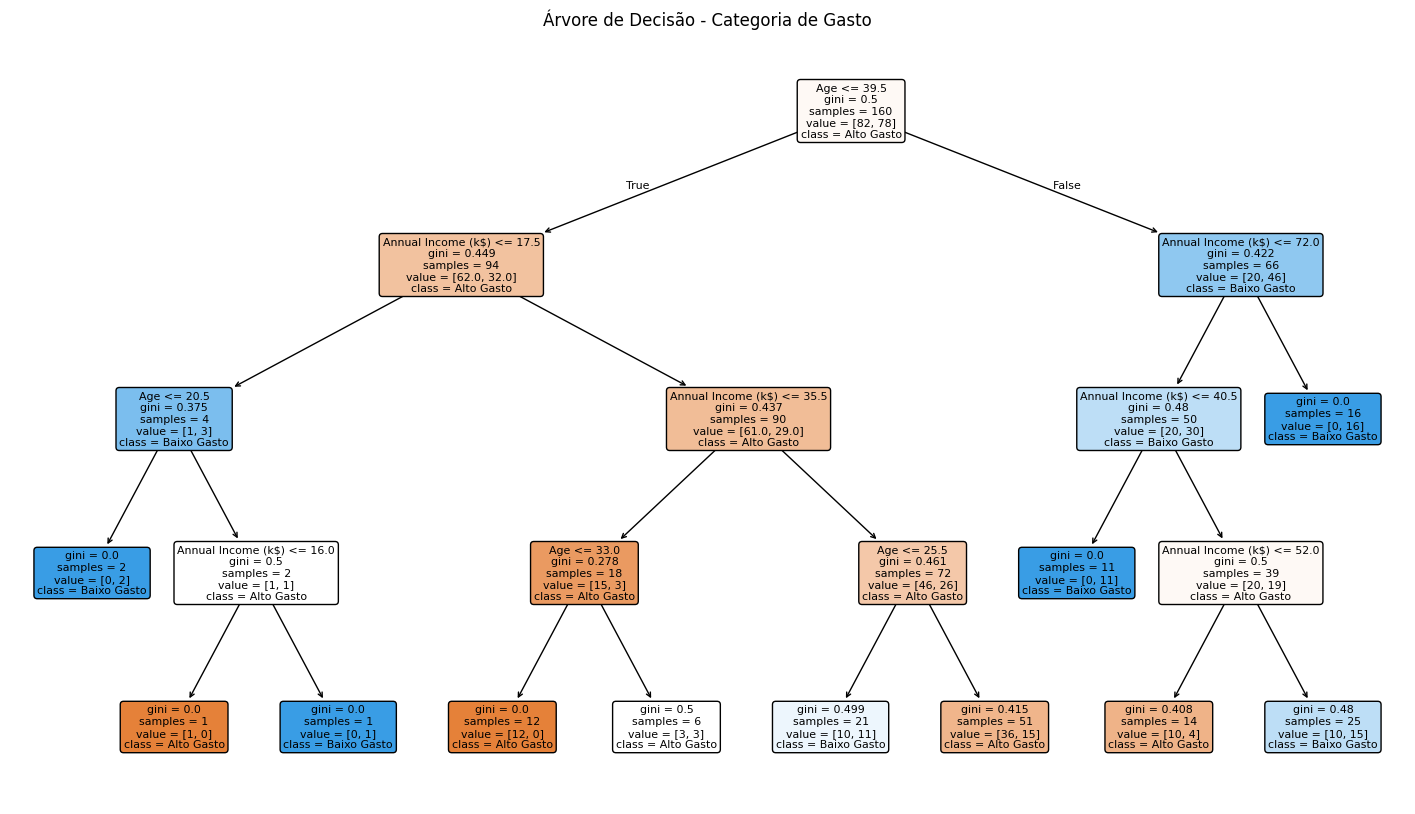

In [14]:
plt.figure(figsize=(18, 10))

plot_tree(
    modelo_arvore,
    feature_names=X.columns,
    class_names=modelo_arvore.classes_,
    filled=True,
    rounded=True
)

plt.title("Árvore de Decisão - Categoria de Gasto")

plt.show()

In [ ]:
#PARTE 2 — K-MEANS#

In [15]:
X_kmeans = df[
    [
        "Annual Income (k$)",
        "Spending Score (1-100)"
    ]
]

In [16]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_kmeans)

In [17]:
wcss = []

for k in range(1, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    wcss.append(kmeans.inertia_)

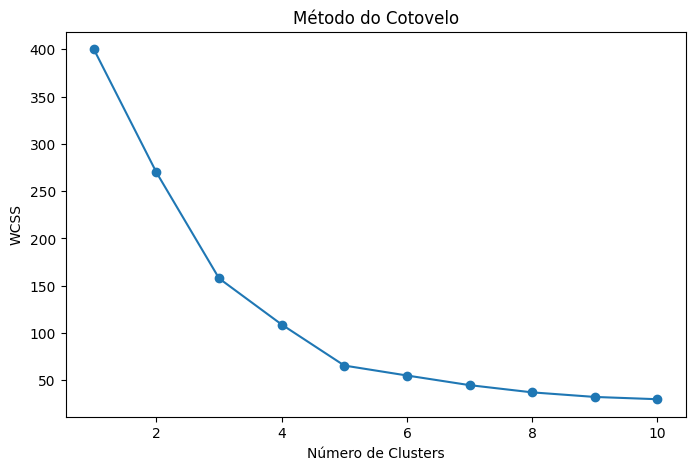

In [18]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 11),
    wcss,
    marker="o"
)

plt.xlabel("Número de Clusters")
plt.ylabel("WCSS")
plt.title("Método do Cotovelo")

plt.show()

In [19]:
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_scaled)

df["Cluster"] = clusters

df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Categoria_Gasto,Cluster
0,1,Male,19,15,39,Baixo Gasto,4
1,2,Male,21,15,81,Alto Gasto,2
2,3,Female,20,16,6,Baixo Gasto,4
3,4,Female,23,16,77,Alto Gasto,2
4,5,Female,31,17,40,Baixo Gasto,4


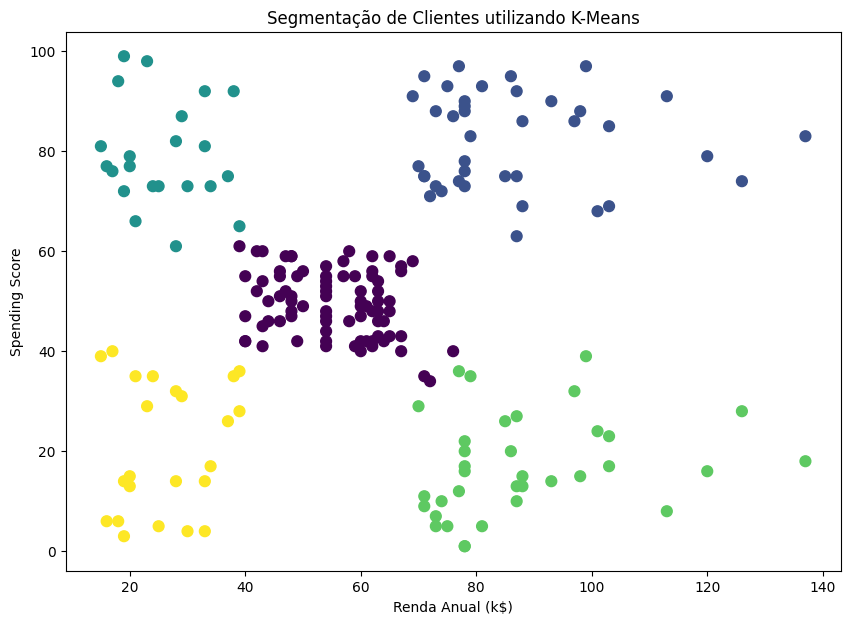

In [20]:
plt.figure(figsize=(10, 7))

plt.scatter(
    df["Annual Income (k$)"],
    df["Spending Score (1-100)"],
    c=df["Cluster"],
    s=60
)

plt.xlabel("Renda Anual (k$)")
plt.ylabel("Spending Score")
plt.title("Segmentação de Clientes utilizando K-Means")

plt.show()

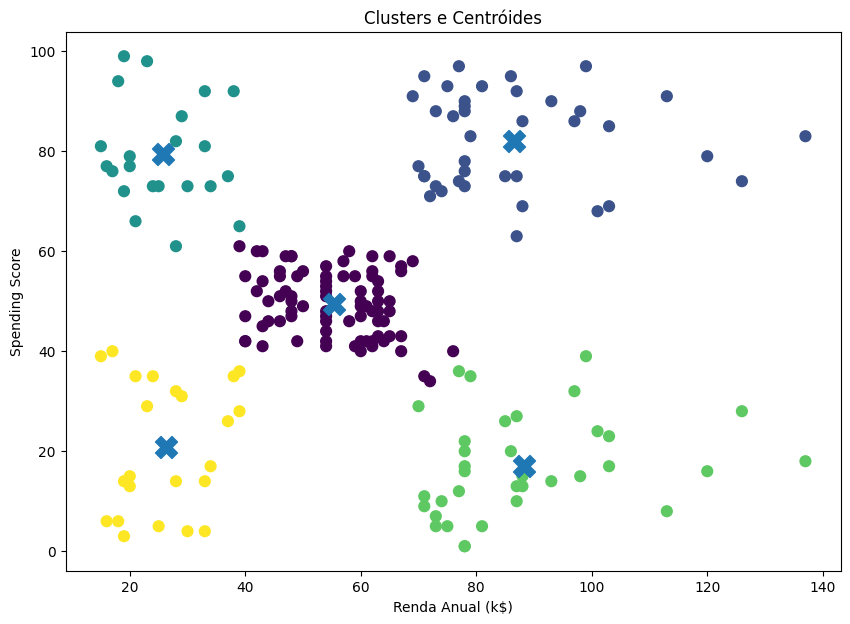

In [21]:
centroides = scaler.inverse_transform(
    kmeans.cluster_centers_
)

plt.figure(figsize=(10, 7))

plt.scatter(
    df["Annual Income (k$)"],
    df["Spending Score (1-100)"],
    c=df["Cluster"],
    s=60
)

plt.scatter(
    centroides[:, 0],
    centroides[:, 1],
    marker="X",
    s=250
)

plt.xlabel("Renda Anual (k$)")
plt.ylabel("Spending Score")

plt.title("Clusters e Centróides")

plt.show()

In [22]:
analise_clusters = df.groupby("Cluster")[
    [
        "Age",
        "Annual Income (k$)",
        "Spending Score (1-100)"
    ]
].mean()

print(analise_clusters)

               Age  Annual Income (k$)  Spending Score (1-100)
Cluster                                                       
0        42.716049           55.296296               49.518519
1        32.692308           86.538462               82.128205
2        25.272727           25.727273               79.363636
3        41.114286           88.200000               17.114286
4        45.217391           26.304348               20.913043


In [23]:
print(df["Cluster"].value_counts())

Cluster
0    81
1    39
3    35
4    23
2    22
Name: count, dtype: int64
